# Phân tích AI4I 2020 và kết quả giữa kỳ

Notebook đọc bộ kết quả đã chạy tại `results/final/`. Các độ đo là validation, chưa đánh giá test. Dùng `python -m ai4i` từ thư mục gốc để chạy một bộ thực nghiệm mới.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd() if (Path.cwd() / 'ai4i').is_dir() else Path.cwd().parent
RESULTS = ROOT / 'results' / 'final'
assert (RESULTS / 'completion.json').exists(), 'Hãy chạy python -m ai4i trước.'
quality = json.loads((RESULTS / 'eda' / 'data_quality.json').read_text(encoding='utf-8'))
display(pd.Series(quality).to_frame('Giá trị'))

,Giá trị
rows,10000
columns,14
missing_cells,0
duplicate_rows,0
failure_count,339
failure_percent,3.39
decision,Keep source target and valid outliers; no miss...
mode_mismatch_count,27


## Dữ liệu và cách chia

10.000 dòng, 14 cột. Đầu vào gồm Type và 5 biến số. Loại ID và cờ failure mode khỏi X; giữ nguyên nhãn và điểm cực trị hợp lệ. Encoder/scaler fit riêng trong train hoặc mỗi fold CV.

,split,count,failure_count
0,test,1500,51
1,train,7000,237
2,validation,1500,51


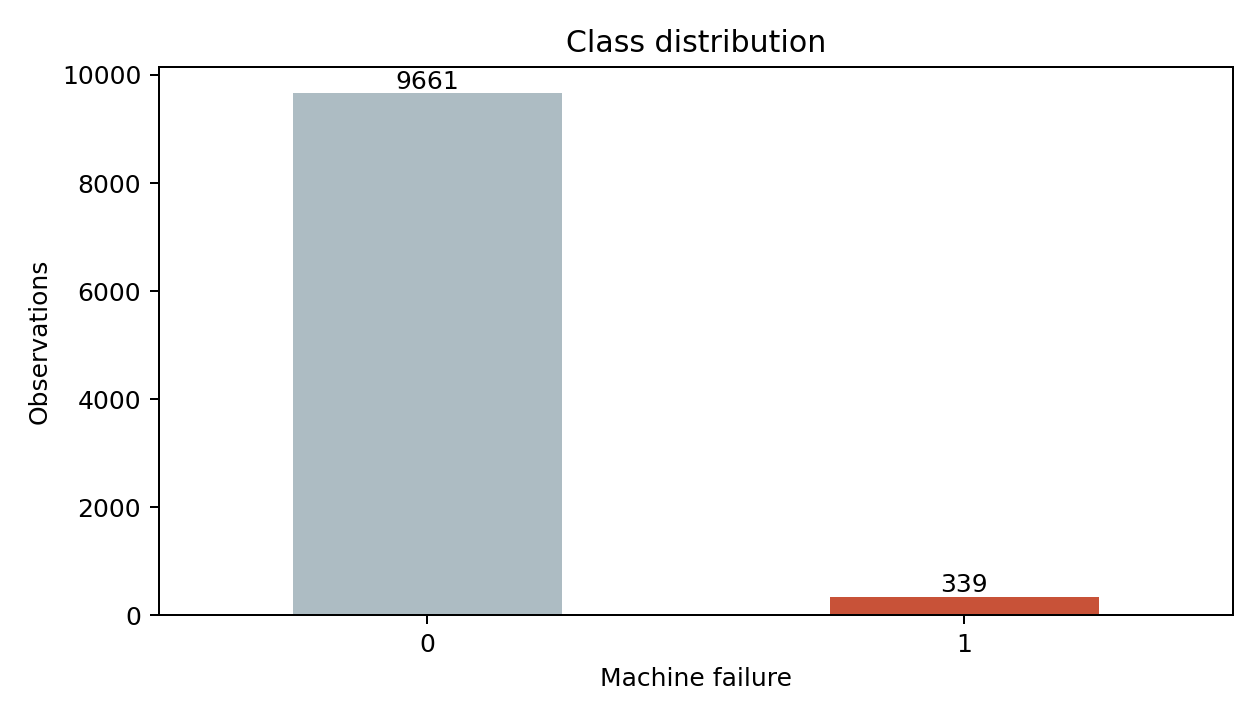

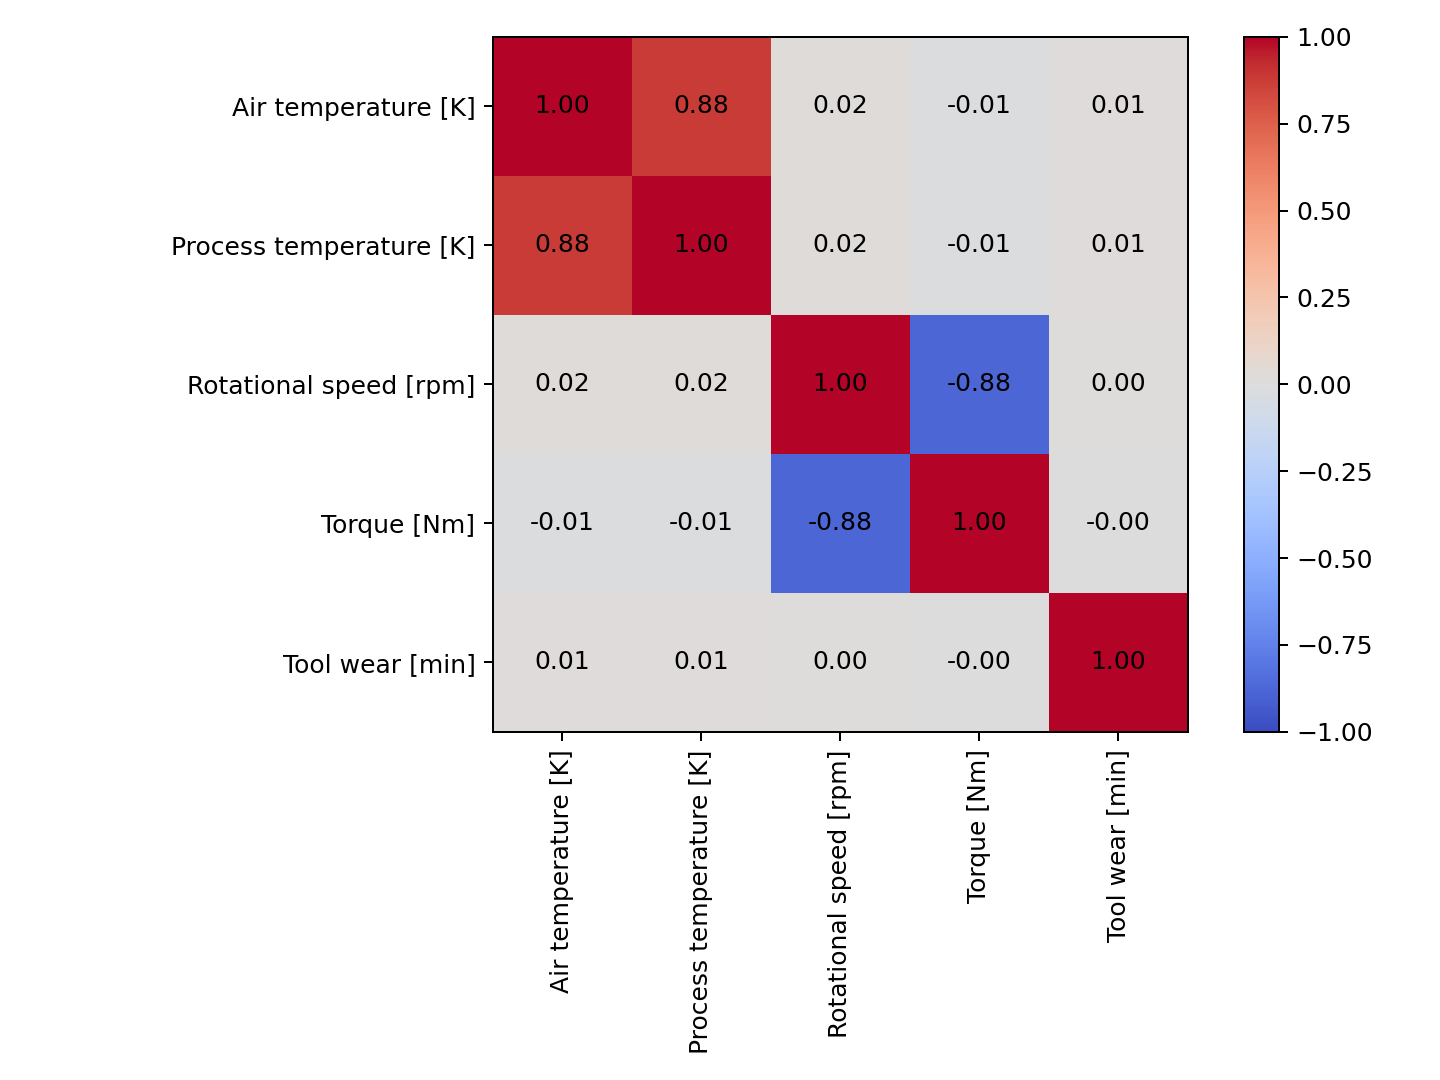

In [2]:
display(pd.read_csv(RESULTS / 'eda' / 'split_summary.csv'))
display(Image(filename=str(RESULTS / 'eda' / 'class_distribution.png')))
display(Image(filename=str(RESULTS / 'eda' / 'correlation.png')))

## Kết quả 17 mô hình

E00 là baseline. E01 thêm đặc trưng. E02 tuning biến gốc. E03 tuning biến mở rộng. CV phân tầng 3 fold chỉ trên train, refit theo F1 lớp lỗi.

,run,model,started_at,precision,recall,f1,roc_auc,fn,fp
0,E00,Dummy,2026-11-06T16:34:34+07:00,0.000000,0.000000,0.000000,0.500000,51,0
1,E00,LogisticRegression,2026-11-06T16:34:34+07:00,0.136531,0.725490,0.229814,0.875032,14,234
2,E00,DecisionTree,2026-11-06T16:34:34+07:00,0.330357,0.725490,0.453988,0.742101,14,75
3,E00,RandomForest,2026-11-06T16:34:34+07:00,0.702703,0.509804,0.590909,0.973870,25,11
4,E00,GradientBoosting,2026-11-06T16:34:36+07:00,0.882353,0.588235,0.705882,0.977172,21,4
5,E01,LogisticRegression,2026-11-06T16:34:37+07:00,0.169492,0.784314,0.278746,0.904789,11,196
6,E01,DecisionTree,2026-11-06T16:34:37+07:00,0.440367,0.941176,0.600000,0.949553,3,61
7,E01,RandomForest,2026-11-06T16:34:37+07:00,0.926829,0.745098,0.826087,0.980128,13,3
8,E01,GradientBoosting,2026-11-06T16:34:39+07:00,1.000000,0.843137,0.914894,0.982571,8,0
9,E02,LogisticRegression,2026-11-06T16:34:41+07:00,0.137037,0.725490,0.230530,0.874856,14,233


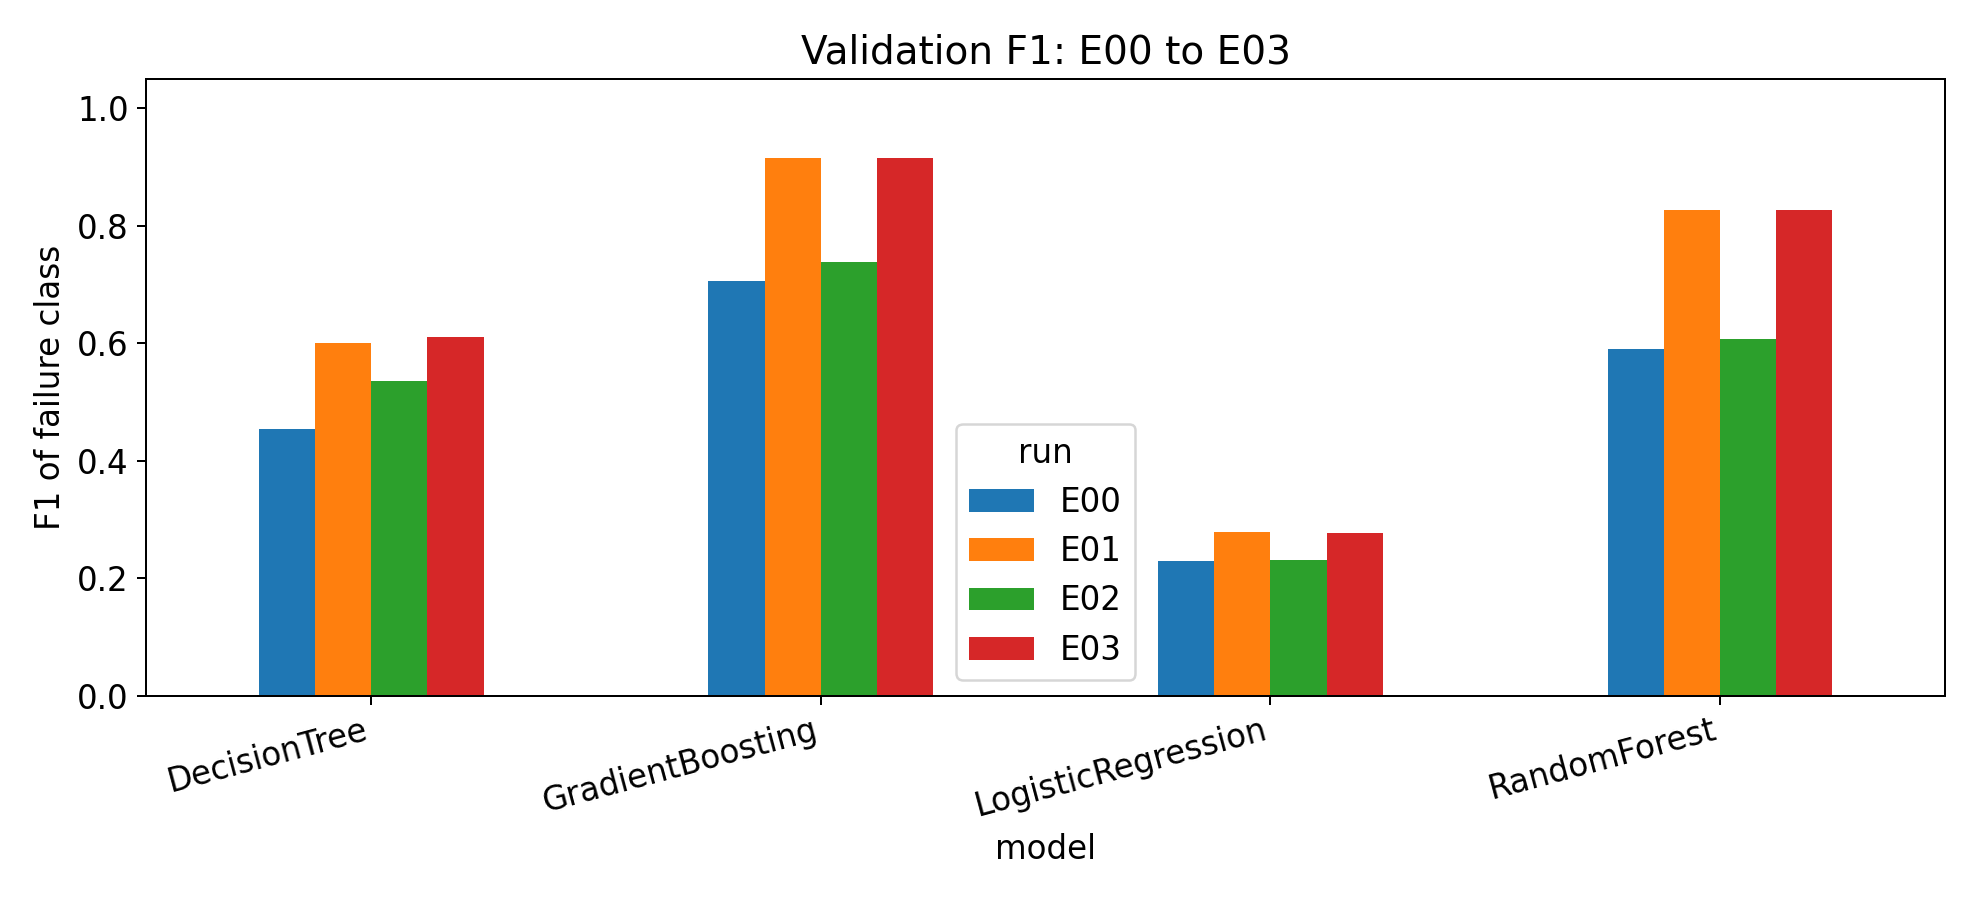

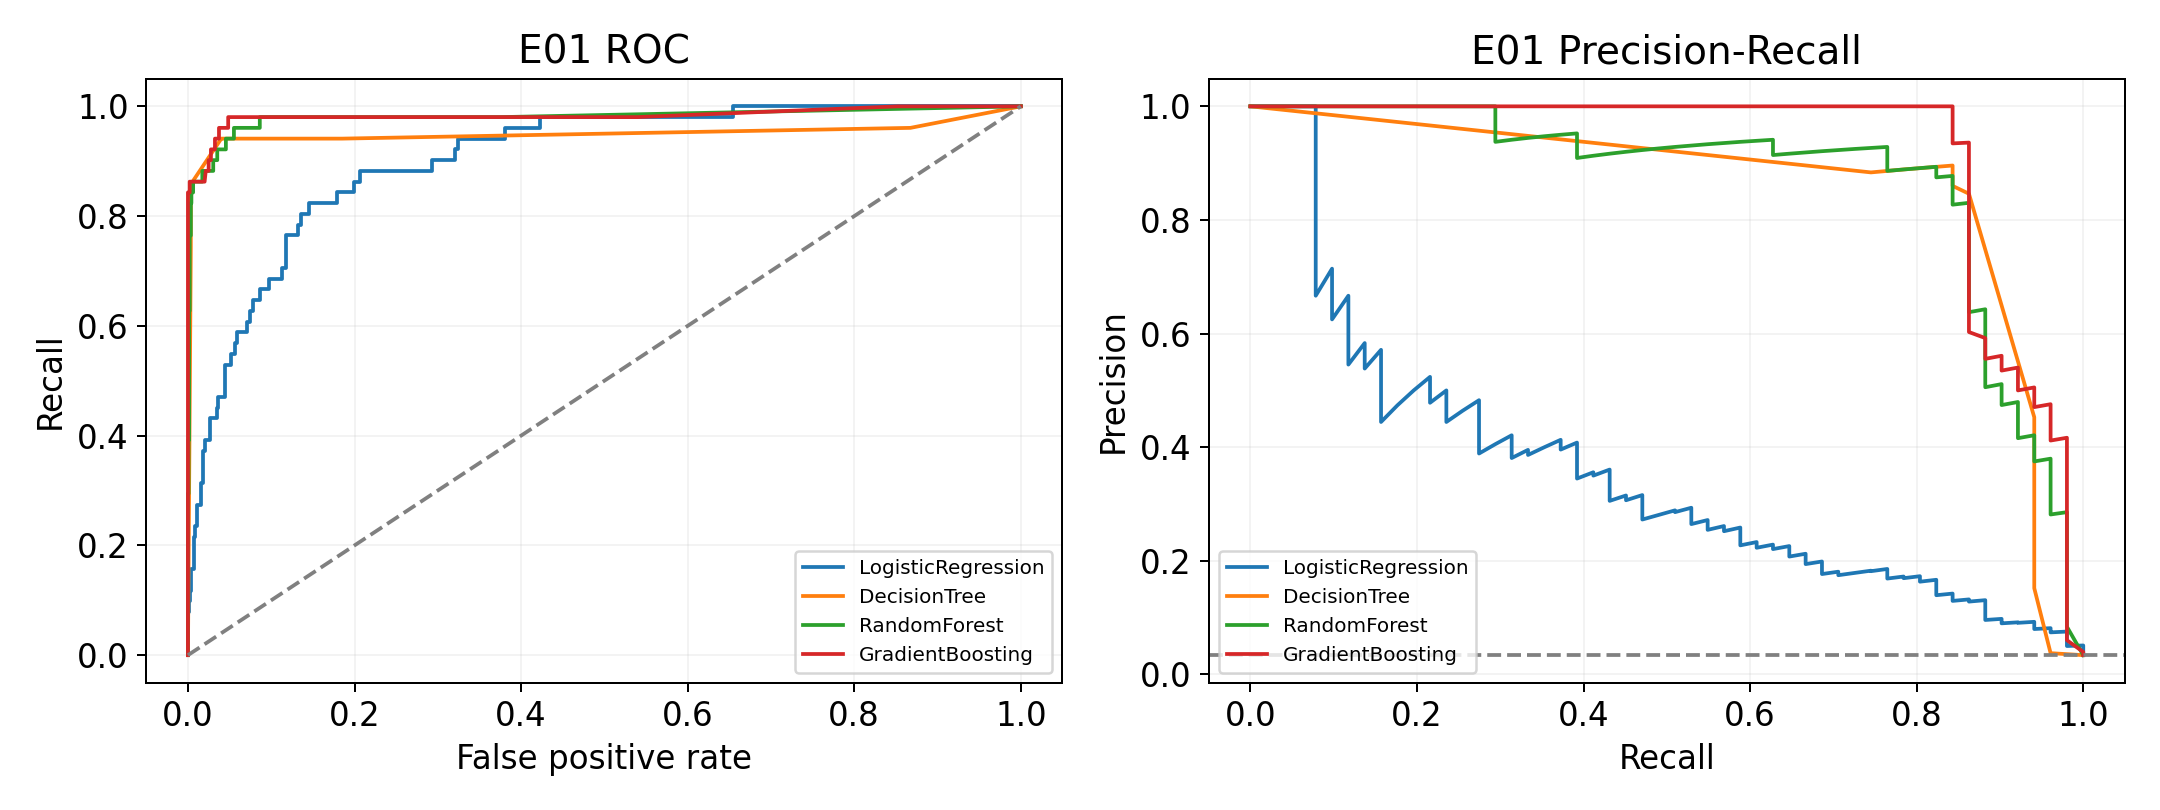

In [3]:
log = pd.read_csv(RESULTS / 'experiment_log.csv')
display(log[['run', 'model', 'started_at', 'precision', 'recall', 'f1', 'roc_auc', 'fn', 'fp']])
display(Image(filename=str(RESULTS / 'all_rounds_f1.png')))
display(Image(filename=str(RESULTS / 'roc_pr_e01.png')))

## Minh chứng và kiểm tra tái lập

Permutation importance của báo cáo đo từng cột sau tạo đặc trưng. Đây là độ nhạy của mô hình, không phải bằng chứng nhân quả. Ở bản nộp cuối, tạo đặc trưng được tích hợp trong pipeline đã lưu.

,feature,mean_f1_decrease,std
0,Air temperature [K],0.003457,0.007832
1,Torque [Nm],0.021205,0.004769
2,Process temperature [K],0.036848,0.006417
3,Type,0.040350,0.008227
4,Tool wear [min],0.056429,0.009064
5,Estimated power [W],0.199104,0.000000
6,Wear torque [minNm],0.220316,0.017313
7,Temperature difference [K],0.404489,0.041371
8,Rotational speed [rpm],0.414590,0.019101


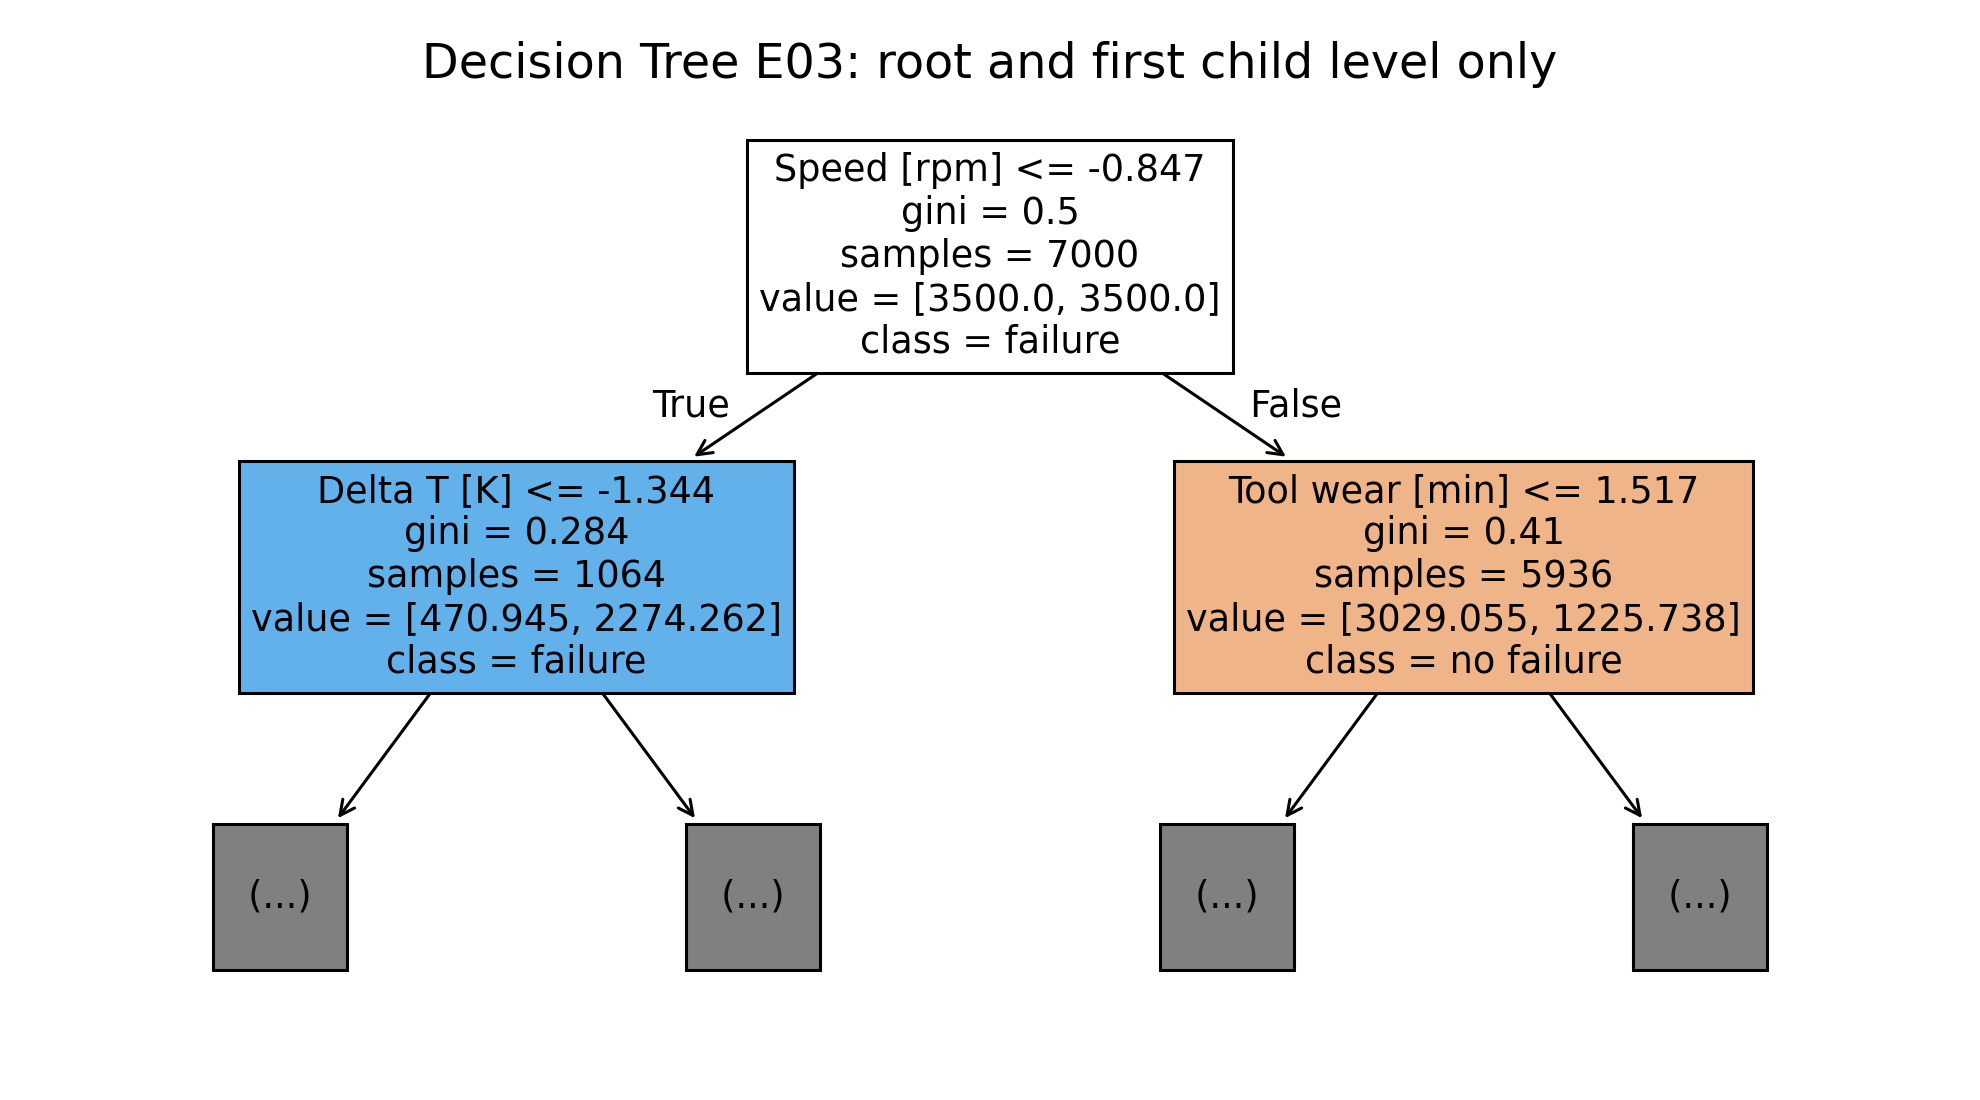

completed_at             2026-11-06T16:35:37+07:00
successful_runs                                 17
baseline_runs                                    5
additional_runs                                 12
execution_error_count                            0
warning_count                                    0
verified_models                                 17
test_evaluated                               False
dtype: object

passed                                                          True
verified_models                                                   17
checks             [disjoint complete split, validation row IDs a...
test_evaluated                                                 False
dtype: object

In [4]:
display(pd.read_csv(RESULTS / 'algorithm_evidence' / 'GradientBoosting' / 'permutation_importance.csv'))
display(Image(filename=str(RESULTS / 'algorithm_evidence' / 'DecisionTree' / 'model_structure.png')))
display(pd.Series(json.loads((RESULTS / 'completion.json').read_text(encoding='utf-8'))))
display(pd.Series(json.loads((RESULTS / 'verification.json').read_text(encoding='utf-8'))).drop('models'))

## Giới hạn

F1 0,9149 của Gradient Boosting E01/E03 thuộc lần chia validation này. Dữ liệu mô phỏng, validation chỉ có 51 lỗi và đã dùng nhiều lần để so sánh. Cần chốt ngưỡng và mô hình trước khi đánh giá test. Nhóm bổ sung đóng góp cá nhân và hạn hoàn thành vào tài liệu trước khi nộp.